In [7]:
import os, subprocess, sys, time, datetime
T_START = time.time(); _T_CELL = [T_START]


def cell_done(n, name):
    now = time.time()
    fmt = lambda s: str(datetime.timedelta(seconds=int(s)))
    print(f'✅ Cell {n} ({name}) завершено за {fmt(now - _T_CELL[0])} | від старту {fmt(now - T_START)} | '
          f'{datetime.datetime.now():%H:%M:%S}', flush=True)
    _T_CELL[0] = now


IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/HiARN/E4_AXP'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'anchor-exp', 'tqdm'], check=False)
else:
    OUT = os.environ.get('AXP_OUT', './axp_out')
os.makedirs(OUT, exist_ok=True)
print('OUT =', OUT)
print('CPU:', os.cpu_count())
cell_done(1, 'Drive, пакети')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OUT = /content/drive/MyDrive/HiARN/E4_AXP
CPU: 2
✅ Cell 1 (Drive, пакети) завершено за 0:00:12 | від старту 0:00:12 | 11:11:46


In [8]:
import itertools, json, math, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from multiprocessing import Pool
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier


EPOCHS, N_RULES, K, GAMMA, TAU0, TAU_END, TAU_G, RHO = 500, 32, 3, 2.0, 0.7, 0.1, 0.98, 0.1
LAMS = [1e-4, 1e-3, 1e-2, 3e-2]
LRS = {'T': [5e-4, 3e-3], 'NDNF': [3e-3, 1e-2], 'HiARN-C': [3e-3, 1e-2], 'CPROD': [3e-3, 1e-2]}
VARIANTS = ['T', 'NDNF', 'HiARN-C', 'CPROD']
CART_DEPTHS = [2, 3, 4, 5, 6]
F1_TOL, N_BOOT = 0.01, 2000
SMOKE = os.environ.get('AXP_SMOKE') == '1'
if SMOKE:
    EPOCHS, LAMS, LRS = 20, [1e-3], {v: l[:1] for v, l in LRS.items()}


def load_datasets():
    D = {}
    bc = load_breast_cancer()
    D['breast_cancer'] = (bc.data.astype(np.float32), bc.target.astype(np.int64))
    df = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv', header=None)
    fn = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigree', 'Age']
    df.columns = fn + ['Outcome']
    for c in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
        df[c] = df[c].replace(0, np.nan).fillna(df[c].median())
    D['pima_diabetes'] = (df[fn].values.astype(np.float32), df['Outcome'].values.astype(np.int64))
    raw = pd.read_csv('https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv')
    keep = ['sex', 'age', 'race', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'priors_count',
            'days_b_screening_arrest', 'c_charge_degree']
    df = raw[keep + ['two_year_recid']].copy().dropna()
    df = df[(df['days_b_screening_arrest'] <= 30) & (df['days_b_screening_arrest'] >= -30)]
    for c in ['sex', 'race', 'c_charge_degree']:
        df[c] = LabelEncoder().fit_transform(df[c])
    D['compas'] = (df[keep].values.astype(np.float32), df['two_year_recid'].values.astype(np.int64))
    return D


def get_tau(ep):
    return TAU_END + (TAU0 - TAU_END) * (TAU_G ** ep)


def get_delta(ep):
    return min(1.0, 0.1 * 10 ** (ep / (0.6 * EPOCHS)))


class ModelT(nn.Module):
    def __init__(self, X, y, n_cls):
        super().__init__()
        F = X.shape[1]
        thr = np.median(X, 0).copy()
        for j in range(F):
            t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X[:, j:j + 1], y).tree_.threshold[0]
            if t > -2: thr[j] = t
        self.t = nn.Parameter(torch.tensor(thr, dtype=torch.float32))
        self.W = nn.Parameter(torch.empty(N_RULES, F)); nn.init.xavier_uniform_(self.W)
        self.Wo = nn.Parameter(torch.empty(n_cls, N_RULES)); nn.init.xavier_uniform_(self.Wo)
        self.b = nn.Parameter(torch.zeros(n_cls))

    def forward(self, x, tau, delta):
        s = torch.sigmoid(GAMMA * (x - self.t) / tau)
        return torch.sigmoid(s @ self.W.T / tau) @ self.Wo.T + self.b

    def l1_params(self): return [self.W, self.Wo]

    def discrete(self, x):
        with torch.no_grad():
            s = (x > self.t).float()
            W = self.W
            keep = (W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0)
            Wp = W * keep
            alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & keep.any(1)
            a = ((s @ Wp.T) > 0).float() * alive.float()
            return a @ self.Wo.T + self.b, keep, alive, torch.arange(x.shape[1]).repeat(1)


class ModelSemi(nn.Module):
    def __init__(self, X, y, n_cls, learn):
        super().__init__()
        F = X.shape[1]
        self.learn = learn
        q = np.quantile(X, [0.25, 0.5, 0.75], axis=0).T.astype(np.float32)
        self.t = nn.Parameter(torch.tensor(q), requires_grad=learn)
        L = F * K
        self.W = nn.Parameter(torch.empty(N_RULES, L)); nn.init.xavier_uniform_(self.W)
        self.Wo = nn.Parameter(torch.empty(n_cls, N_RULES)); nn.init.xavier_uniform_(self.Wo)
        self.b = nn.Parameter(torch.zeros(n_cls))

    def lits(self, x, tau, hard):
        z = x[:, :, None] - self.t[None]
        a = torch.where(z > 0, 1.0, -1.0) if (hard or not self.learn) else 2 * torch.sigmoid(GAMMA * z / tau) - 1
        return a.reshape(x.shape[0], -1)

    def conj(self, a, delta):
        beta = delta * (self.W.abs().max(1).values - self.W.abs().sum(1))
        return (torch.tanh(a @ self.W.T + beta) + 1) / 2

    def forward(self, x, tau, delta):
        return self.conj(self.lits(x, tau, False), delta) @ self.Wo.T + self.b

    def l1_params(self): return [self.W, self.Wo]

    def discrete(self, x):
        with torch.no_grad():
            a = self.lits(x, 0, True)
            W = self.W
            keep = (W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0)
            ok = (torch.sign(W)[None] * a[:, None, :] > 0) | ~keep[None]
            fires = ok.all(2).float()
            has = keep.any(1)
            fires = torch.where(has[None], fires, torch.full_like(fires, 0.5))
            alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & has
            used = fires * (alive | ~has).float()
            return used @ self.Wo.T + self.b, keep, alive, torch.arange(x.shape[1]).repeat_interleave(K)


class ModelCProd(nn.Module):
    def __init__(self, X, y, n_cls):
        super().__init__()
        F = X.shape[1]
        q = np.quantile(X, [0.25, 0.5, 0.75], axis=0).T.astype(np.float32)
        self.t = nn.Parameter(torch.tensor(q))
        self.u = nn.Parameter(torch.randn(N_RULES, 2 * F * K) * 0.5 - 1.0)
        self.Wo = nn.Parameter(torch.empty(n_cls, N_RULES)); nn.init.xavier_uniform_(self.Wo)
        self.b = nn.Parameter(torch.zeros(n_cls))

    def lits(self, x, tau, hard):
        z = x[:, :, None] - self.t[None]
        l = (z > 0).float() if hard else torch.sigmoid(GAMMA * z / tau)
        l = l.reshape(x.shape[0], -1)
        return torch.cat([l, 1 - l], 1)

    def forward(self, x, tau, delta):
        w = torch.sigmoid(self.u)
        l = self.lits(x, tau, False)
        a = torch.exp(torch.log((1 - w[None] * (1 - l[:, None, :])).clamp(min=1e-6)).sum(2))
        return a @ self.Wo.T + self.b

    def l1_params(self): return [self.Wo]

    def l1_extra(self): return torch.sigmoid(self.u).sum()

    def discrete(self, x):
        with torch.no_grad():
            l = self.lits(x, 0, True)
            keep = torch.sigmoid(self.u) > 0.5
            fires = ((l[:, None, :] > 0.5) | ~keep[None]).all(2).float()
            has = keep.any(1)
            alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & has
            used = fires * (alive | ~has).float()
            F = x.shape[1]
            return used @ self.Wo.T + self.b, keep, alive, torch.arange(F).repeat_interleave(K).repeat(2)


def build(variant, X, y, n_cls):
    return {'T': lambda: ModelT(X, y, n_cls), 'NDNF': lambda: ModelSemi(X, y, n_cls, False),
            'HiARN-C': lambda: ModelSemi(X, y, n_cls, True), 'CPROD': lambda: ModelCProd(X, y, n_cls)}[variant]()


def train_eval(args):
    variant, cfg, X_tr, y_tr, X_te, y_te, seed = args
    torch.set_num_threads(1)
    torch.manual_seed(seed); np.random.seed(seed)
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = build(variant, X_tr, y_tr, n_cls)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    cnt = np.bincount(y_tr, minlength=n_cls)
    lossf = nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (n_cls * cnt), dtype=torch.float32), label_smoothing=0.05)
    opt = torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=cfg['lr'])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    lam = cfg['lam']
    for ep in range(EPOCHS):
        tau, delta = get_tau(ep), get_delta(ep)
        opt.zero_grad()
        loss = lossf(m(Xt, tau, delta), yt) + lam * sum(p.abs().sum() for p in m.l1_params())
        if hasattr(m, 'l1_extra'): loss = loss + lam * m.l1_extra()
        loss.backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        with torch.no_grad():
            for p in m.l1_params():
                p.data = torch.sign(p.data) * (p.data.abs() - lam * cfg['lr']).clamp(min=0)
        sch.step()
    Xe = torch.tensor(X_te)
    with torch.no_grad():
        p_soft = m(Xe, TAU_END, 1.0).argmax(1).numpy()
        lg, keep, alive, feat_of_lit = m.discrete(Xe)
    p_hard = lg.argmax(1).numpy()
    lens = keep[alive].sum(1).numpy()
    feats = sorted(set(feat_of_lit[keep[alive].any(0)].tolist())) if alive.any() else []
    return {'rules_f1': float(f1_score(y_te, p_hard, average='macro', zero_division=0)),
            'model_f1': float(f1_score(y_te, p_soft, average='macro', zero_division=0)),
            'fidelity': float((p_hard == p_soft).mean()),
            'n_rules': int(alive.sum()), 'total_conditions': int(lens.sum()),
            'avg_len': float(lens.mean()) if len(lens) else 0.0,
            'degenerate': bool(len(np.unique(p_hard)) == 1), 'features': feats}


def cart_eval(X_tr, y_tr, X_te, y_te, depth, seed):
    clf = DecisionTreeClassifier(max_depth=depth, class_weight='balanced', random_state=seed).fit(X_tr, y_tr)
    t = clf.tree_; d = np.zeros(t.node_count, int)
    for i in range(t.node_count):
        for ch in (t.children_left[i], t.children_right[i]):
            if ch != -1: d[ch] = d[i] + 1
    leaves = np.where(t.children_left == -1)[0]
    p = clf.predict(X_te)
    return {'rules_f1': float(f1_score(y_te, p, average='macro', zero_division=0)), 'n_rules': int(len(leaves)),
            'total_conditions': int(d[leaves].sum()), 'avg_len': float(d[leaves].mean()),
            'degenerate': bool(len(np.unique(p)) == 1),
            'features': sorted(set(int(f) for f in t.feature if f >= 0))}


def ripper_eval(X_tr, y_tr, X_te, y_te, seed):
    import wittgenstein as lw
    cols = [f'f{j}' for j in range(X_tr.shape[1])]
    rip = lw.RIPPER(random_state=seed)
    rip.fit(pd.DataFrame(X_tr, columns=cols).assign(y=y_tr.astype(int)), class_feat='y', pos_class=1)
    p = np.array(rip.predict(pd.DataFrame(X_te, columns=cols))).astype(int)
    lens = [len(r.conds) for r in rip.ruleset_.rules]
    feats = sorted({int(c.feature[1:]) for r in rip.ruleset_.rules for c in r.conds})
    return {'rules_f1': float(f1_score(y_te, p, average='macro', zero_division=0)), 'n_rules': len(lens),
            'total_conditions': int(sum(lens)), 'avg_len': float(np.mean(lens)) if lens else 0.0,
            'degenerate': bool(len(np.unique(p)) == 1), 'features': feats}


def splits(X, y, confirm):
    if confirm:
        it = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if SMOKE else 3, random_state=2026).split(X, y)
    else:
        it = StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y)
    out = []
    for tr, te in it:
        sc = StandardScaler().fit(X[tr])
        out.append((sc.transform(X[tr]).astype(np.float32), y[tr], sc.transform(X[te]).astype(np.float32), y[te]))
    return out


def mean_of(rows, k): return float(np.mean([r[k] for r in rows]))


def select(rows_by_cfg):
    best = max(mean_of(r, 'rules_f1') for r in rows_by_cfg.values())
    ok = {c: r for c, r in rows_by_cfg.items() if mean_of(r, 'rules_f1') >= best - F1_TOL}
    return min(ok, key=lambda c: mean_of(ok[c], 'total_conditions'))


def jaccard(rows):
    s = [set(r['features']) for r in rows]
    v = [len(a & b) / len(a | b) if (a | b) else 1.0 for a, b in itertools.combinations(s, 2)]
    return float(np.mean(v))


def summarize(rows):
    return {k: [round(mean_of(rows, k), 4), round(float(np.std([r[k] for r in rows])), 4)]
            for k in ('rules_f1', 'n_rules', 'total_conditions', 'avg_len') } | \
           ({'model_f1': [round(mean_of(rows, 'model_f1'), 4)], 'fidelity': [round(mean_of(rows, 'fidelity'), 4)]}
            if 'fidelity' in rows[0] else {}) | \
           {'degenerate_rate': round(mean_of(rows, 'degenerate'), 4), 'feature_jaccard': round(jaccard(rows), 4)}


def paired_ci(a, b, seed=42):
    a, b = np.array(a), np.array(b); rng = np.random.RandomState(seed)
    d = [(a[i] - b[i]).mean() for i in (rng.randint(0, len(a), len(a)) for _ in range(N_BOOT))]
    return [round(float((a - b).mean()), 4), round(float(np.percentile(d, 2.5)), 4), round(float(np.percentile(d, 97.5)), 4)]


cell_done(2, 'дані, спліти, варіанти ядра')

✅ Cell 2 (дані, спліти, варіанти ядра) завершено за 0:00:00 | від старту 0:00:12 | 11:11:46


In [9]:
import itertools, json, sys, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from multiprocessing import Pool
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier


EPOCHS, LR, TAU0, TAUE, TAUG, GAMMA, RHO, F1_TOL = 500, 3e-3, 0.7, 0.03, 0.98, 2.0, 0.1, 0.01
TOPK, N_CONCEPTS, TOPK_FROM = 3, 8, 0.3
LAMS = [1e-4, 1e-3, 1e-2]
CFGS = ([{'model': 'H2', 'rules': r, 'lam': l} for r in (8, 16, 32) for l in LAMS]
        + [{'model': 'H3c', 'rules': r, 'lam': l} for r in (8, 16) for l in LAMS]
        + [{'model': 'H3', 'rules': 16, 'lam': l} for l in LAMS])
SMOKE = os.environ.get('AXP_SMOKE') == '1'
if SMOKE:
    EPOCHS, CFGS = 15, [c for c in CFGS if c['lam'] == 1e-3][:3] + [c for c in CFGS if c['model'] != 'H2' and c['lam'] == 1e-3]


def ckey(c): return f'{c["model"]}|r={c["rules"]}|lam={c["lam"]}'


class Net(nn.Module):
    def __init__(self, X, y, n_cls, cfg):
        super().__init__()
        F = X.shape[1]
        thr = np.median(X, 0).copy()
        for j in range(F):
            t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X[:, j:j + 1], y).tree_.threshold[0]
            if t > -2: thr[j] = t
        self.t = nn.Parameter(torch.tensor(thr, dtype=torch.float32))
        self.kind = cfg['model']
        h1 = {'H2': cfg['rules'], 'H3': 32, 'H3c': N_CONCEPTS}[self.kind]
        self.W1 = nn.Parameter(torch.empty(h1, F)); nn.init.xavier_uniform_(self.W1)
        last = h1
        if self.kind != 'H2':
            self.W2 = nn.Parameter(torch.empty(cfg['rules'], h1)); nn.init.xavier_uniform_(self.W2)
            last = cfg['rules']
        self.Wo = nn.Parameter(torch.empty(n_cls, last)); nn.init.xavier_uniform_(self.Wo)
        self.b = nn.Parameter(torch.zeros(n_cls))

    def and_ws(self): return [self.W1] + ([self.W2] if self.kind != 'H2' else [])

    def forward(self, x, tau):
        a = torch.sigmoid(torch.sigmoid(GAMMA * (x - self.t) / tau) @ self.W1.T / tau)
        if self.kind != 'H2': a = torch.sigmoid(a @ self.W2.T / tau)
        return a @ self.Wo.T + self.b

    def discrete(self, x):
        with torch.no_grad():
            def prune(W):
                return (W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0)
            s = (x > self.t).float()
            k1 = prune(self.W1); c = ((s @ (self.W1 * k1).T) > 0).float()
            if self.kind == 'H2':
                alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & k1.any(1)
                a = c * alive
                lens = k1[alive].sum(1)
                dl = int(lens.sum()); feats = set(torch.where(k1[alive].any(0))[0].tolist())
                return a @ self.Wo.T + self.b, {'dl': dl, 'n_rules': int(alive.sum()),
                        'items_per_rule': float(lens.float().mean()) if alive.any() else 0.0,
                        'expanded_len': float(lens.float().mean()) if alive.any() else 0.0, 'feats': feats}
            k2 = prune(self.W2) & k1.any(1)[None]
            r = ((c @ (self.W2 * k2).T) > 0).float()
            alive = (self.Wo.abs().max(0).values >= RHO * self.Wo.abs().max()) & k2.any(1)
            used_c = k2[alive].any(0)
            conc_len = k1.sum(1)
            dl = int(conc_len[used_c].sum() + k2[alive].sum())
            exp_len = [(conc_len[k2[i]]).sum().item() for i in torch.where(alive)[0]]
            feats = set(torch.where(k1[used_c].any(0))[0].tolist()) if used_c.any() else set()
            return (r * alive) @ self.Wo.T + self.b, {'dl': dl, 'n_rules': int(alive.sum()), 'n_concepts': int(used_c.sum()),
                    'items_per_rule': float(k2[alive].sum(1).float().mean()) if alive.any() else 0.0,
                    'expanded_len': float(np.mean(exp_len)) if exp_len else 0.0, 'feats': feats}


def topk_project(W, k):
    with torch.no_grad():
        idx = W.abs().topk(min(k, W.shape[1]), dim=1).indices
        W.data *= torch.zeros_like(W).scatter_(1, idx, 1.0)


def run(args):
    cfg, X_tr, y_tr, X_te, y_te, seed = args
    torch.set_num_threads(1); torch.manual_seed(seed); np.random.seed(seed)
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = Net(X_tr, y_tr, n_cls, cfg)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    cnt = np.bincount(y_tr, minlength=n_cls)
    lossf = nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (n_cls * cnt), dtype=torch.float32), label_smoothing=0.05)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    lam = cfg['lam']
    for ep in range(EPOCHS):
        tau = TAUE + (TAU0 - TAUE) * TAUG ** ep
        opt.zero_grad()
        loss = lossf(m(Xt, tau), yt) + lam * (sum(W.abs().sum() for W in m.and_ws()) + m.Wo.abs().sum())
        loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        with torch.no_grad():
            for W in m.and_ws() + [m.Wo]:
                W.data = torch.sign(W.data) * (W.data.abs() - lam * LR).clamp(min=0)
        if m.kind == 'H3c' and ep >= int(TOPK_FROM * EPOCHS):
            topk_project(m.W1, TOPK); topk_project(m.W2, TOPK)
        sch.step()
    Xe = torch.tensor(X_te)
    with torch.no_grad():
        p_soft = m(Xe, TAUE).argmax(1).numpy()
        lg, info = m.discrete(Xe)
    p = lg.argmax(1).numpy()
    info['feats'] = sorted(info['feats'])
    return {'rules_f1': float(f1_score(y_te, p, average='macro', zero_division=0)),
            'fidelity': float((p == p_soft).mean()), 'degenerate': bool(len(np.unique(p)) == 1), **info}


def mean(rows, k): return float(np.mean([r[k] for r in rows]))


def jacc(rows):
    s = [set(r['feats']) for r in rows]
    return float(np.mean([len(a & b) / len(a | b) if (a | b) else 1.0 for a, b in itertools.combinations(s, 2)]))


def summ(rows):
    out = {k: round(mean(rows, k), 4) for k in ('rules_f1', 'fidelity', 'dl', 'n_rules', 'items_per_rule', 'expanded_len', 'degenerate')}
    if 'n_concepts' in rows[0]: out['n_concepts'] = round(mean(rows, 'n_concepts'), 2)
    out['feature_jaccard'] = round(jacc(rows), 3)
    return out


cell_done(3, 'HiARN-2 / HiARN-3')

✅ Cell 3 (HiARN-2 / HiARN-3) завершено за 0:00:00 | від старту 0:00:12 | 11:11:46


In [10]:
import json, sys, time
from pathlib import Path
import numpy as np
import torch
from multiprocessing import Pool
from scipy.optimize import milp, LinearConstraint, Bounds


CFG = {'H2': {'breast_cancer': {'model': 'H2', 'rules': 8, 'lam': 1e-2},
              'pima_diabetes': {'model': 'H2', 'rules': 32, 'lam': 1e-4},
              'compas':        {'model': 'H2', 'rules': 8, 'lam': 1e-2}},
       'H3': {'breast_cancer': {'model': 'H3', 'rules': 16, 'lam': 1e-2},
              'pima_diabetes': {'model': 'H3', 'rules': 16, 'lam': 1e-4},
              'compas':        {'model': 'H3', 'rules': 16, 'lam': 1e-2}}}
RHO, N_VERIFY, N_CMP = 0.1, 200, 100
SMOKE = os.environ.get('AXP_SMOKE') == '1'
if SMOKE: EPOCHS, N_CMP = 20, 5


def train(cfg, X_tr, y_tr, n_cls, seed):
    torch.set_num_threads(1); torch.manual_seed(seed); np.random.seed(seed)
    m = Net(X_tr, y_tr, n_cls, cfg)
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr)
    cnt = np.bincount(y_tr, minlength=n_cls)
    lossf = torch.nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (n_cls * cnt), dtype=torch.float32), label_smoothing=0.05)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
    lam = cfg['lam']
    for ep in range(EPOCHS):
        tau = TAUE + (TAU0 - TAUE) * TAUG ** ep
        opt.zero_grad()
        loss = lossf(m(Xt, tau), yt) + lam * (sum(W.abs().sum() for W in m.and_ws()) + m.Wo.abs().sum())
        loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        with torch.no_grad():
            for W in m.and_ws() + [m.Wo]: W.data = torch.sign(W.data) * (W.data.abs() - lam * LR).clamp(min=0)
        sch.step()
    return m


def parts_of(m):
    with torch.no_grad():
        def prune(W): return ((W.abs() >= RHO * W.abs().max(1, keepdim=True).values) & (W.abs() > 0))
        k1 = prune(m.W1); W1 = (m.W1 * k1)
        if m.kind == 'H2':
            alive = (m.Wo.abs().max(0).values >= RHO * m.Wo.abs().max()) & k1.any(1)
            layers = [W1[alive].numpy().astype(np.float64)]
        else:
            k2 = prune(m.W2) & k1.any(1)[None]
            alive = (m.Wo.abs().max(0).values >= RHO * m.Wo.abs().max()) & k2.any(1)
            layers = [W1.numpy().astype(np.float64), (m.W2 * k2)[alive].numpy().astype(np.float64)]
        return m.t.numpy(), layers, m.Wo[:, alive].numpy().astype(np.float64), m.b.numpy().astype(np.float64)


def predict(P, S):
    _, layers, Wo, b = P
    a = S
    for W in layers: a = ((a @ W.T) > 0).astype(float)
    return (a @ Wo.T + b).argmax(1)


def sufficient_bounds(P, s, fixed, c_hat):
    _, layers, Wo, b = P
    lo = np.where(fixed, s, 0.0); hi = np.where(fixed, s, 1.0)
    for W in layers:
        Wp, Wn = np.maximum(W, 0), np.minimum(W, 0)
        zlo, zhi = lo @ Wp.T + hi @ Wn.T, hi @ Wp.T + lo @ Wn.T
        lo, hi = (zlo > 0).astype(float), (zhi > 0).astype(float)
    for c in range(Wo.shape[0]):
        if c == c_hat: continue
        d = Wo[c_hat] - Wo[c]
        if (np.minimum(d * lo, d * hi)).sum() + b[c_hat] - b[c] <= 0: return False
    return True


def sufficient_milp(P, s, fixed, c_hat):
    _, layers, Wo, b = P
    free = np.where(~fixed)[0]; nf = len(free)
    sizes = [W.shape[0] for W in layers]
    nv = nf + sum(sizes)
    for c in range(Wo.shape[0]):
        if c == c_hat: continue
        A, lb, ub = [], [], []
        prev_idx, prev_const = None, None
        off = nf
        for li, W in enumerate(layers):
            for r in range(W.shape[0]):
                row = np.zeros(nv); const = 0.0
                if li == 0:
                    const = float((W[r] * s)[fixed].sum()); row[:nf] = W[r][free]
                else:
                    row[prev_idx] = W[r]
                M = np.abs(W[r]).sum() + abs(const) + 1.0
                a = off + r
                r1 = row.copy(); r1[a] = -M; A.append(r1); lb.append(-np.inf); ub.append(-const)
                r2 = row.copy(); r2[a] = -M; A.append(r2); lb.append(1e-6 - M - const); ub.append(np.inf)
            prev_idx = np.arange(off, off + W.shape[0]); off += W.shape[0]
        d = Wo[c] - Wo[c_hat]
        obj = np.zeros(nv); obj[prev_idx] = -d
        res = milp(obj, constraints=LinearConstraint(np.array(A), lb, ub), integrality=np.ones(nv),
                   bounds=Bounds(0, 1), options={'presolve': False})
        if res.status != 0: return False
        if -res.fun + b[c] - b[c_hat] >= 0: return False
    return True


def explain(P, s, check):
    _, layers, Wo, b = P
    c_hat = int(predict(P, s[None])[0])
    used = np.abs(layers[0]).sum(0) > 0
    fixed = used.copy()
    imp = np.abs(layers[0]).sum(0)
    for j in np.argsort(imp):
        if not fixed[j]: continue
        fixed[j] = False
        if not check(P, s, fixed, c_hat): fixed[j] = True
    return c_hat, fixed


def violations(P, s, keep, c_hat, S_tr, rng):
    free = ~keep
    R = np.repeat(s[None], 2 * N_VERIFY, 0)
    R[:N_VERIFY][:, free] = rng.randint(0, 2, (N_VERIFY, free.sum()))
    R[N_VERIFY:][:, free] = S_tr[rng.randint(0, len(S_tr), N_VERIFY)][:, free]
    return bool((predict(P, R) != c_hat).any())


_CMP_CNT = None


def _init_worker(cnt):
    global _CMP_CNT
    _CMP_CNT = cnt


def _tick():
    if _CMP_CNT is not None:
        with _CMP_CNT.get_lock(): _CMP_CNT.value += 1


def run_fold(args):
    arch, ds, X_tr, y_tr, X_te, y_te, seed, compare = args
    n_cls = int(max(y_tr.max(), y_te.max()) + 1)
    m = train(CFG[arch][ds], X_tr, y_tr, n_cls, seed)
    P = parts_of(m); t = P[0]
    S_te, S_tr = (X_te > t).astype(np.float64), (X_tr > t).astype(np.float64)
    rng = np.random.RandomState(seed)
    out = {'ours_len': [], 'ours_ms': [], 'ours_viol': 0, 'n': len(S_te)}
    for i in range(len(S_te)):
        t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[i], sufficient_bounds); out['ours_ms'].append(1000 * (time.perf_counter() - t0))
        out['ours_len'].append(int(fx.sum())); out['ours_viol'] += violations(P, S_te[i], fx, c_hat, S_tr, rng)
    if compare:
        from anchor import anchor_tabular
        pred_fn = lambda Xr: predict(P, (Xr > t).astype(np.float64))
        ex = anchor_tabular.AnchorTabularExplainer([str(c) for c in range(n_cls)], [f'f{j}' for j in range(X_tr.shape[1])], X_tr)
        out.update({'cmp_ours_len': out['ours_len'][:N_CMP], 'cmp_ours_ms': out['ours_ms'][:N_CMP],
                    'milp_len': [], 'milp_ms': [], 'anchor_len': [], 'anchor_ms': [], 'anchor_viol': 0, 'milp_viol': 0})
        for i in range(min(N_CMP, len(S_te))):
            t0 = time.perf_counter(); c_hat, fx = explain(P, S_te[i], sufficient_milp); out['milp_ms'].append(1000 * (time.perf_counter() - t0))
            out['milp_len'].append(int(fx.sum())); out['milp_viol'] += violations(P, S_te[i], fx, c_hat, S_tr, rng)
            t0 = time.perf_counter()
            e = ex.explain_instance(X_te[i], pred_fn, threshold=0.95)
            out['anchor_ms'].append(1000 * (time.perf_counter() - t0))
            feats = sorted({int(nm.split(' ')[0][1:]) if nm.split(' ')[0].startswith('f') else int(nm.split(' ')[2][1:])
                            for nm in e.names()}) if e.names() else []
            keep = np.zeros(X_tr.shape[1], bool); keep[feats] = True
            out['anchor_len'].append(len(feats))
            Xr = np.repeat(X_te[i][None], N_VERIFY, 0)
            Xr[:, ~keep] = X_tr[rng.randint(0, len(X_tr), N_VERIFY)][:, ~keep]
            out['anchor_viol'] += bool((pred_fn(Xr) != int(predict(P, S_te[i][None])[0])).any())
            _tick()
    return out


cell_done(4, 'пояснення, MILP, Anchors')

✅ Cell 4 (пояснення, MILP, Anchors) завершено за 0:00:00 | від старту 0:00:12 | 11:11:46


In [11]:
import multiprocessing as mp
from tqdm.auto import tqdm

ARCHS = ('H2', 'H3')
PART = f'{OUT}/axp_partial' + ('_smoke' if SMOKE else '')
os.makedirs(PART, exist_ok=True)
N_PROC = min(10, os.cpu_count() or 1)


def _pfile(ds, arch, i): return f'{PART}/{ds}_{arch}_{i}.json'


def main():
    t0 = time.time(); D = load_datasets()
    res = {'status': 'OFFICIAL (Colab)', 'smoke': SMOKE, 'datasets': {}}
    jobs = {}
    for ds, (X, y) in D.items():
        for i, f in enumerate(splits(X, y, True)):
            for arch in ARCHS:
                jobs[(ds, arch, i)] = (arch, ds, *f, 1000 + i, i == 0)
    outs = {}
    for k in jobs:
        if os.path.exists(_pfile(*k)): outs[k] = json.load(open(_pfile(*k), encoding='utf-8'))
    todo = sorted((k for k in jobs if k not in outs), key=lambda k: (k[2] != 0, k))
    n_cmp_total = sum(min(N_CMP, len(jobs[k][5])) for k in todo if k[2] == 0)
    print(f'Фолдів усього {len(jobs)}, уже готово {len(outs)}, до виконання {len(todo)}; процесів {N_PROC}; '
          f'порівнянь MILP+Anchors {n_cmp_total}', flush=True)
    if todo:
        cnt = mp.Value('i', 0)
        bar = tqdm(total=len(jobs), initial=len(outs), desc='Фолди', unit='фолд', smoothing=0)
        bar_c = tqdm(total=n_cmp_total, desc='Порівняння (MILP+Anchors)', unit='вип', smoothing=0)
        with mp.Pool(N_PROC, initializer=_init_worker, initargs=(cnt,)) as pool:
            pend = {k: pool.apply_async(run_fold, (jobs[k],)) for k in todo}
            while pend:
                for k in [k for k, a in pend.items() if a.ready()]:
                    o = pend.pop(k).get()
                    outs[k] = o
                    json.dump(o, open(_pfile(*k), 'w', encoding='utf-8'))
                    bar.update(1)
                    tqdm.write(f'  [{len(outs)}/{len(jobs)}] {k[0]} {k[1]} фолд {k[2]}: n={o["n"]}, '
                               f'медіана {np.median(o["ours_len"]):.0f} умов, порушень {o["ours_viol"]}'
                               + (f' (+ порівняння {len(o["milp_len"])} вип.)' if 'milp_len' in o else '')
                               + f'  [{time.time() - t0:.0f} с]')
                bar_c.n = cnt.value; bar_c.refresh()
                if pend: time.sleep(2)
        bar_c.n = cnt.value; bar_c.refresh(); bar.close(); bar_c.close()
    for ds in D:
        R = {}
        for arch in ARCHS:
            oo = [outs[(ds, arch, i)] for i in sorted(k[2] for k in jobs if k[:2] == (ds, arch))]
            L = np.concatenate([o['ours_len'] for o in oo]); c = oo[0]
            R[arch] = {'ours_median': float(np.median(L)), 'ours_mean': float(L.mean()), 'ours_p90': float(np.percentile(L, 90)),
                       'ours_viol': int(sum(o['ours_viol'] for o in oo)), 'n': int(sum(o['n'] for o in oo)),
                       'ours_ms': float(np.mean(np.concatenate([o['ours_ms'] for o in oo]))),
                       'cmp': {k: (float(np.median(c[k])) if k.endswith('len') else float(np.mean(c[k])))
                               for k in ('cmp_ours_len', 'cmp_ours_ms', 'milp_len', 'milp_ms', 'anchor_len', 'anchor_ms')},
                       'cmp_anchor_viol_share': c['anchor_viol'] / len(c['anchor_len']),
                       'cmp_milp_viol': c['milp_viol'], 'cmp_n': len(c['anchor_len']),
                       'cmp_raw': {k: c[k] for k in ('cmp_ours_len', 'cmp_ours_ms', 'milp_len', 'milp_ms', 'anchor_len', 'anchor_ms')},
                       'ours_len_counts': {str(int(v)): int(n) for v, n in zip(*np.unique(L, return_counts=True))}}
            r = R[arch]; cm = r['cmp']
            print(f'[{ds} {arch}] наш: медіана {r["ours_median"]:.0f} (p90 {r["ours_p90"]:.0f}), {r["ours_ms"]:.2f} мс, '
                  f'порушень {r["ours_viol"]}/{r["n"]} | на {r["cmp_n"]}: наш {cm["cmp_ours_len"]:.0f} умов/{cm["cmp_ours_ms"]:.2f} мс; '
                  f'MILP {cm["milp_len"]:.0f}/{cm["milp_ms"]:.0f} мс (поруш. {r["cmp_milp_viol"]}); '
                  f'Anchors {cm["anchor_len"]:.0f}/{cm["anchor_ms"]:.0f} мс, порушення у {100*r["cmp_anchor_viol_share"]:.0f}% випадків',
                  flush=True)
        h2 = R['H2']
        R['K2'] = bool(h2['cmp']['milp_ms'] >= 10 * h2['cmp']['cmp_ours_ms'] and h2['cmp']['cmp_ours_len'] <= h2['cmp']['milp_len'] + 1)
        R['K3'] = bool(h2['cmp_anchor_viol_share'] > 0 and h2['ours_viol'] == 0)
        res['datasets'][ds] = R
    dd = res['datasets'].values()
    res['verdict'] = {'K1_H3_guarantee': all(d['H3']['ours_viol'] == 0 for d in dd),
                      'K2_datasets': sum(d['K2'] for d in dd), 'K3_datasets': sum(d['K3'] for d in dd)}
    res['verdict']['all'] = res['verdict']['K1_H3_guarantee'] and res['verdict']['K2_datasets'] >= 2 and res['verdict']['K3_datasets'] >= 2
    res['runtime_s'] = round(time.time() - t0, 1); res['n_proc'] = N_PROC
    path = f'{OUT}/' + ('axp_smoke.json' if SMOKE else 'axp_results.json')
    json.dump(res, open(path, 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
    print('VERDICT:', res['verdict']); print('Збережено:', path)
    return res


res = main()
cell_done(5, 'прогін + збереження')

Фолдів усього 90, уже готово 0, до виконання 90; процесів 2; порівнянь MILP+Anchors 600


Фолди:   0%|          | 0/90 [00:00<?, ?фолд/s]

Порівняння (MILP+Anchors):   0%|          | 0/600 [00:00<?, ?вип/s]

  [1/90] breast_cancer H3 фолд 0: n=114, медіана 9 умов, порушень 0 (+ порівняння 100 вип.)  [626 с]
  [2/90] compas H2 фолд 0: n=1235, медіана 2 умов, порушень 0 (+ порівняння 100 вип.)  [666 с]
  [3/90] compas H3 фолд 0: n=1235, медіана 2 умов, порушень 0 (+ порівняння 100 вип.)  [710 с]
  [4/90] pima_diabetes H2 фолд 0: n=154, медіана 7 умов, порушень 0 (+ порівняння 100 вип.)  [774 с]
  [5/90] breast_cancer H2 фолд 0: n=114, медіана 8 умов, порушень 0 (+ порівняння 100 вип.)  [798 с]
  [6/90] breast_cancer H2 фолд 1: n=114, медіана 7 умов, порушень 0  [802 с]
  [7/90] breast_cancer H2 фолд 2: n=114, медіана 7 умов, порушень 0  [804 с]
  [8/90] breast_cancer H2 фолд 3: n=114, медіана 6 умов, порушень 0  [806 с]
  [9/90] breast_cancer H2 фолд 4: n=113, медіана 6 умов, порушень 0  [808 с]
  [10/90] breast_cancer H2 фолд 5: n=114, медіана 10 умов, порушень 0  [810 с]
  [11/90] breast_cancer H2 фолд 6: n=114, медіана 10 умов, порушень 0  [812 с]
  [12/90] breast_cancer H2 фолд 7: n=114,

── UA ──
  збережено fig_axp_length_ua (.png, .svg)


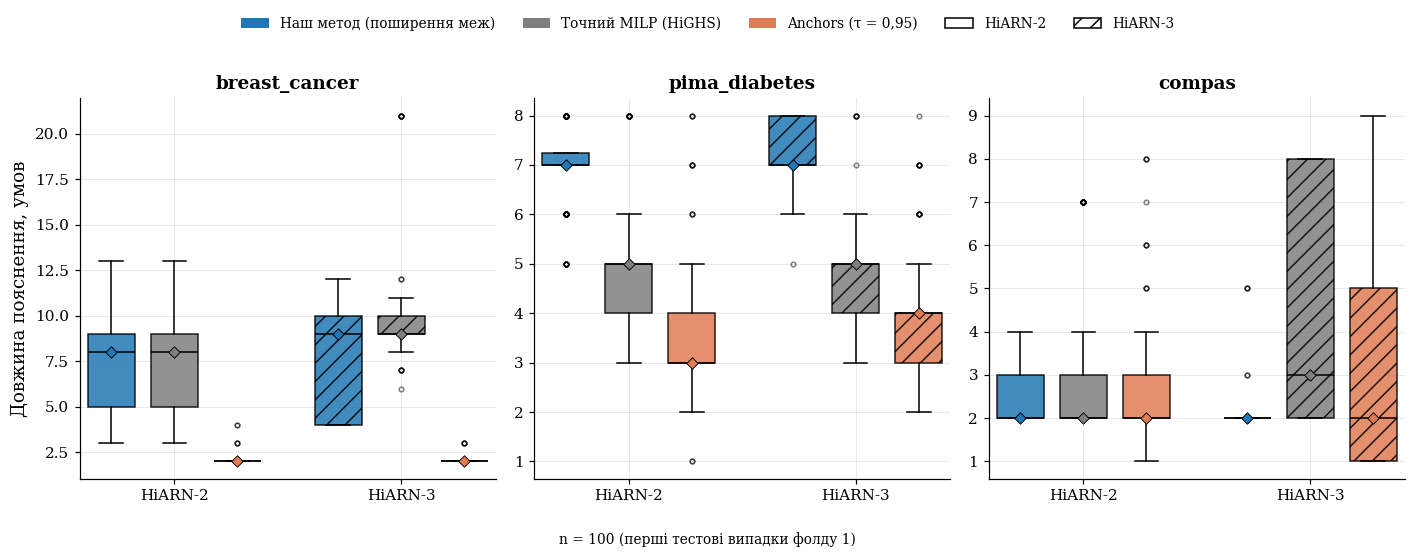

  збережено fig_axp_time_ua (.png, .svg)


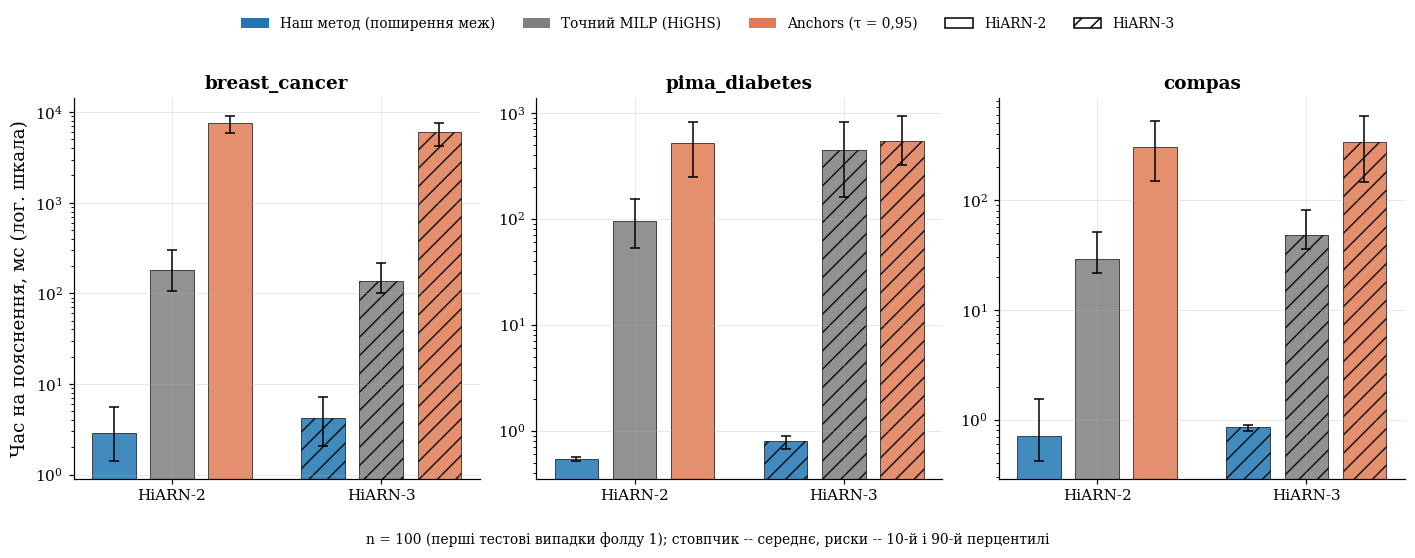

  збережено fig_axp_violations_ua (.png, .svg)


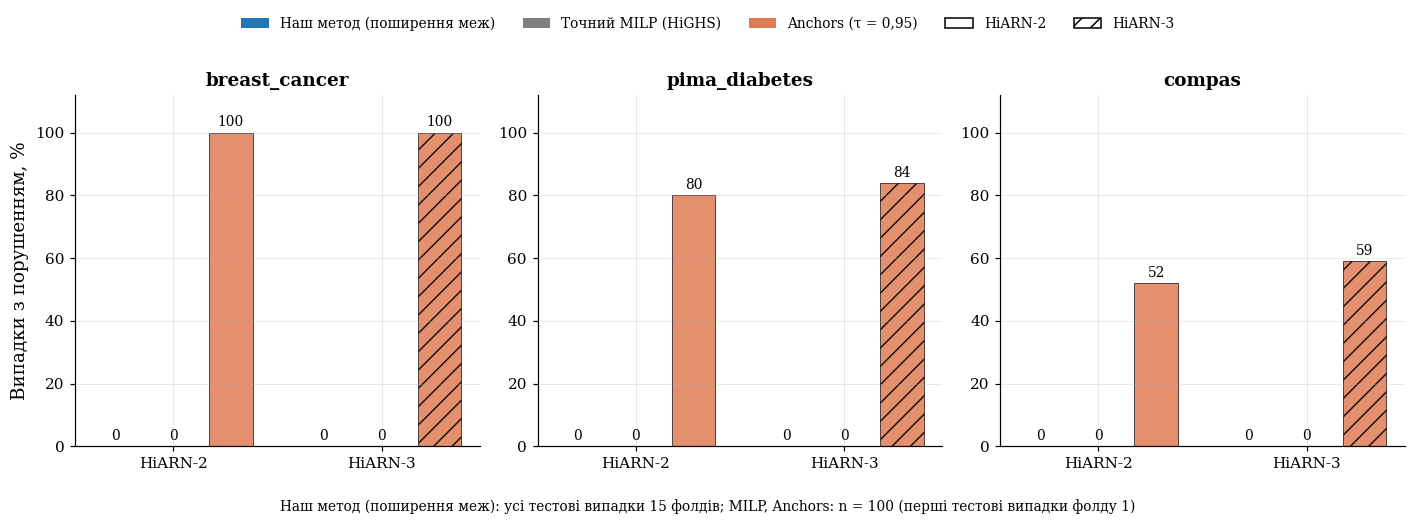

  збережено fig_axp_length_dist_ua (.png, .svg)


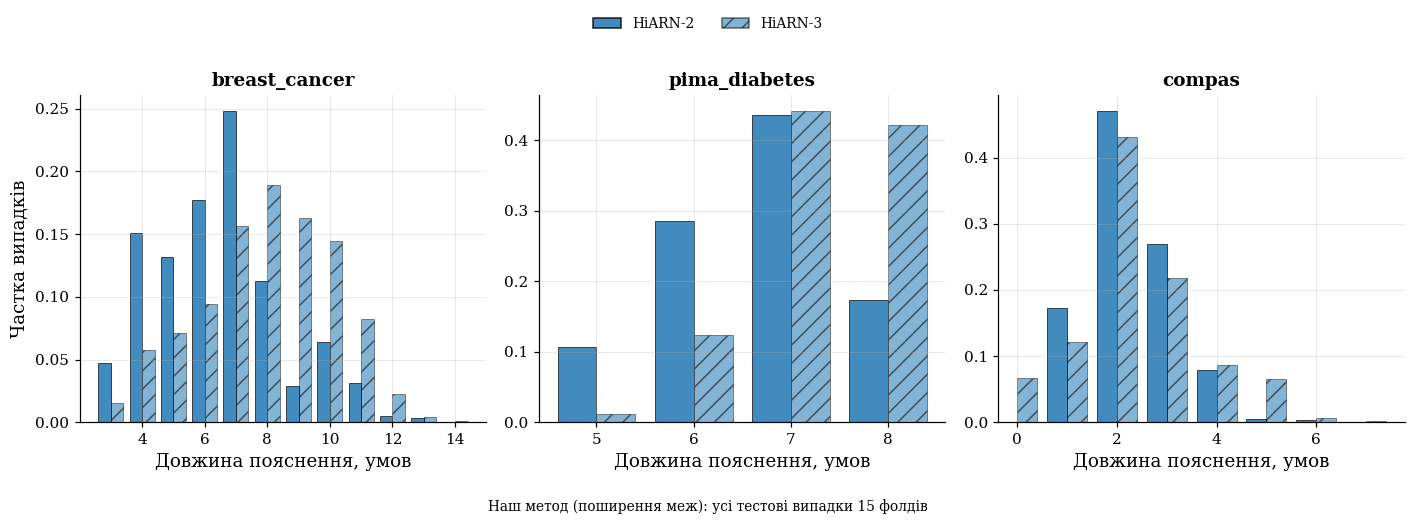

── EN ──
  збережено fig_axp_length_en (.png, .svg)


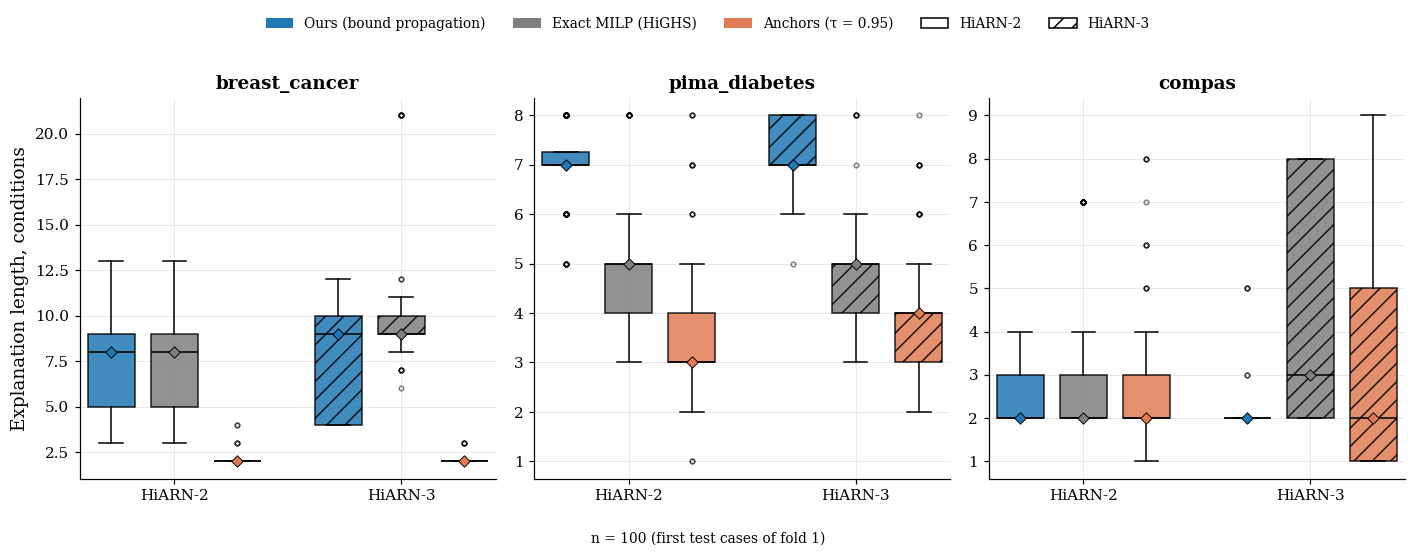

  збережено fig_axp_time_en (.png, .svg)


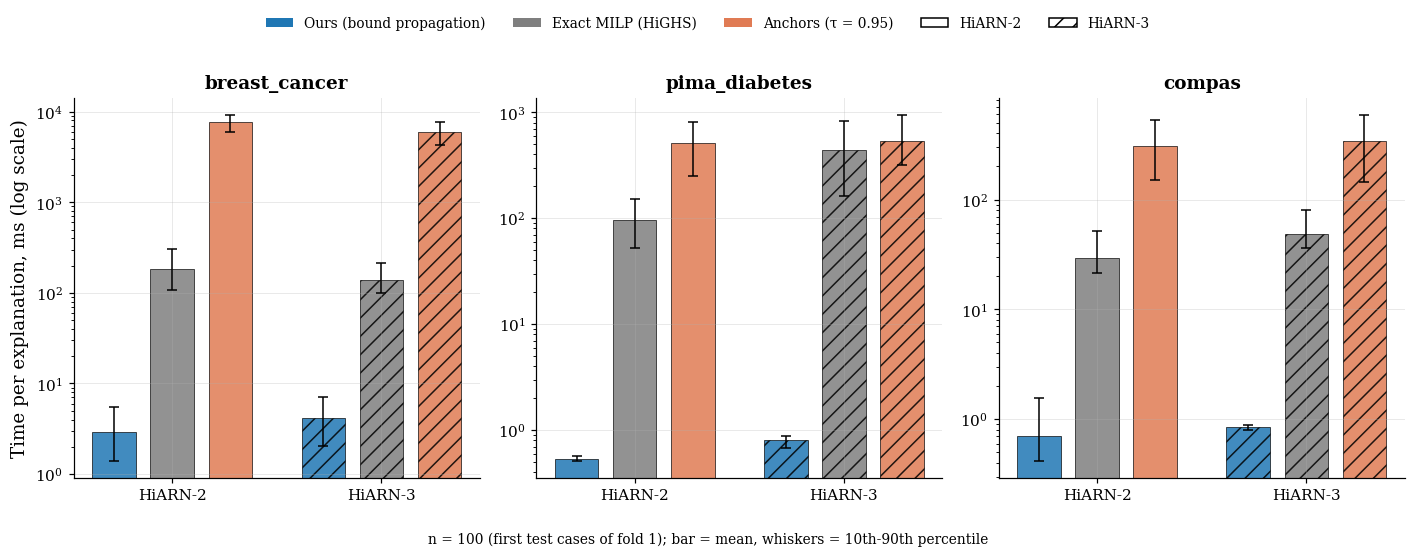

  збережено fig_axp_violations_en (.png, .svg)


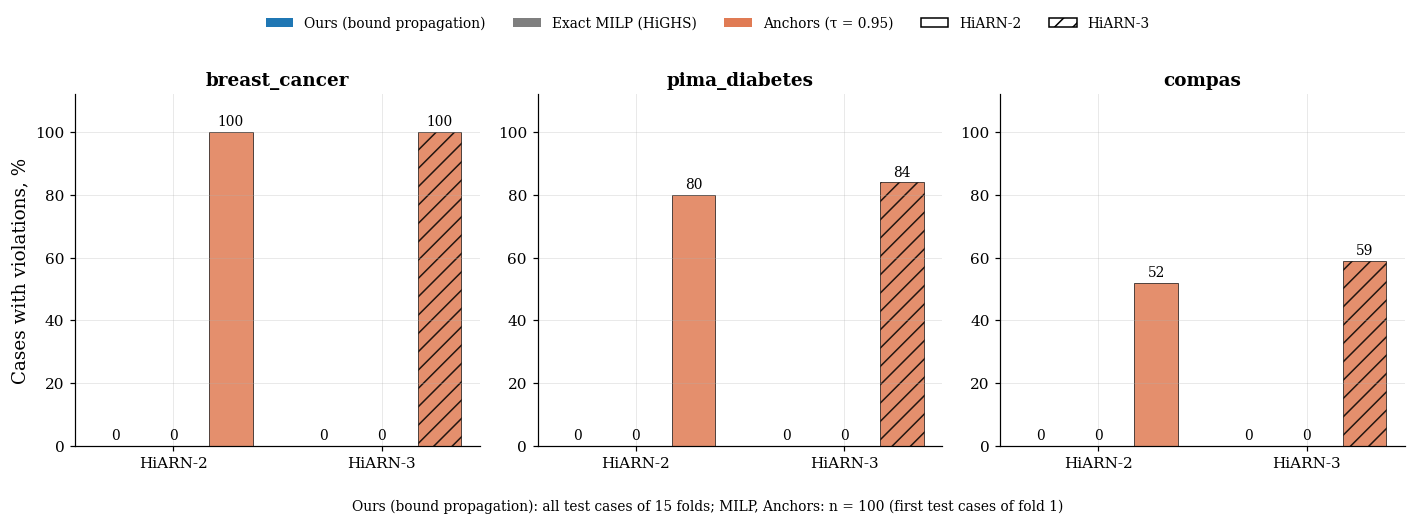

  збережено fig_axp_length_dist_en (.png, .svg)


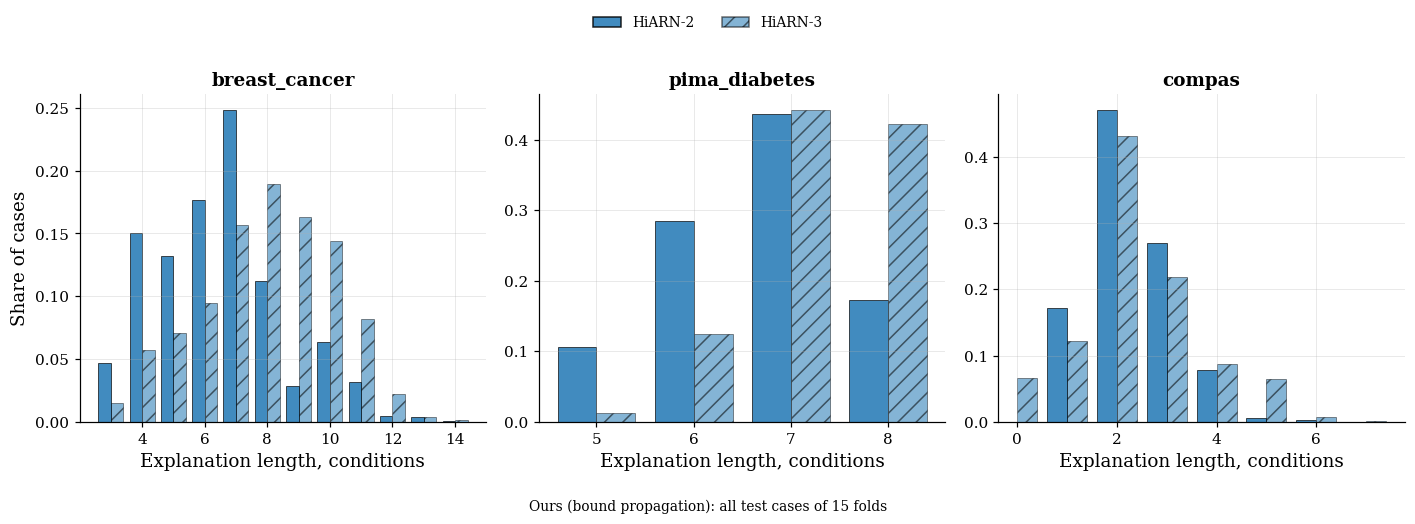

Рисунки: /content/drive/MyDrive/HiARN/E4_AXP/plots
✅ Cell 6 (двомовні графіки) завершено за 0:00:35 | від старту 0:17:07 | 11:28:41
🏁 УСІ КОМІРКИ ЗАВЕРШЕНО


In [12]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if 'res' not in globals():
    res = json.load(open(f'{OUT}/' + ('axp_smoke.json' if SMOKE else 'axp_results.json'), encoding='utf-8'))
PLOT_DIR = f'{OUT}/plots' + ('_smoke' if res.get('smoke') else '')
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'legend.fontsize': 9, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3,
                     'grid.linewidth': 0.6, 'figure.dpi': 110, 'savefig.dpi': 300})
DSETS = list(res['datasets'])
ARCHS = ('H2', 'H3')
ARCH_NAME = {'H2': 'HiARN-2', 'H3': 'HiARN-3'}
METH = ('ours', 'milp', 'anchor')
MCOL = {'ours': '#1f77b4', 'milp': '#7f7f7f', 'anchor': '#e07b54'}
KEYS = {'len': {'ours': 'cmp_ours_len', 'milp': 'milp_len', 'anchor': 'anchor_len'},
        'ms': {'ours': 'cmp_ours_ms', 'milp': 'milp_ms', 'anchor': 'anchor_ms'}}
L = {'ua': {'ours': 'Наш метод (поширення меж)', 'milp': 'Точний MILP (HiGHS)', 'anchor': 'Anchors (τ = 0,95)',
            'len': 'Довжина пояснення, умов', 'ms': 'Час на пояснення, мс (лог. шкала)',
            'viol': 'Випадки з порушенням, %', 'cases': 'Частка випадків',
            'note': 'n = {n} (перші тестові випадки фолду 1)', 'note_all': 'усі тестові випадки 15 фолдів',
            'bar': 'стовпчик -- середнє, риски -- 10-й і 90-й перцентилі'},
     'en': {'ours': 'Ours (bound propagation)', 'milp': 'Exact MILP (HiGHS)', 'anchor': 'Anchors (τ = 0.95)',
            'len': 'Explanation length, conditions', 'ms': 'Time per explanation, ms (log scale)',
            'viol': 'Cases with violations, %', 'cases': 'Share of cases',
            'note': 'n = {n} (first test cases of fold 1)', 'note_all': 'all test cases of 15 folds',
            'bar': 'bar = mean, whiskers = 10th-90th percentile'}}


def save_fig(fig, stem):
    os.makedirs(PLOT_DIR, exist_ok=True)
    for ext in ('png', 'svg'):
        fig.savefig(f'{PLOT_DIR}/{stem}.{ext}', format=ext, dpi=300, bbox_inches='tight', pad_inches=0.05)
    print('  збережено', stem, '(.png, .svg)')


def finish(fig, lang, stem, note, handles):
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(handles), frameon=False)
    fig.text(0.5, 0.0, note, ha='center', va='top', fontsize=9)
    fig.tight_layout(rect=(0, 0.02, 1, 0.9)); save_fig(fig, stem); plt.show(); plt.close(fig)


def meth_handles(lang):
    return ([Patch(facecolor=MCOL[m], label=L[lang][m]) for m in METH]
            + [Patch(facecolor='white', edgecolor='k', label='HiARN-2'),
               Patch(facecolor='white', edgecolor='k', hatch='//', label='HiARN-3')])


def pos(ai, mi): return ai * 3.6 + mi


def axes_common(ax, ds, ylabel):
    ax.set_xticks([pos(0, 1), pos(1, 1)]); ax.set_xticklabels([ARCH_NAME[a] for a in ARCHS])
    ax.set_title(ds); ax.set_ylabel(ylabel if ds == DSETS[0] else '')


def cmp_n(): return res['datasets'][DSETS[0]]['H2']['cmp_n']


def fig_length(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(13, 4.8), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            raw = res['datasets'][ds][a]['cmp_raw']
            for mi, m in enumerate(METH):
                bp = ax.boxplot([raw[KEYS['len'][m]]], positions=[pos(ai, mi)], widths=0.75, patch_artist=True,
                                flierprops={'markersize': 3, 'alpha': 0.5}, medianprops={'color': 'k'})
                bp['boxes'][0].set(facecolor=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '')
                ax.scatter(pos(ai, mi), np.median(raw[KEYS['len'][m]]), marker='D', s=28, color=MCOL[m],
                           edgecolor='k', linewidth=0.6, zorder=3)
        axes_common(ax, ds, L[lang]['len'])
    finish(fig, lang, f'fig_axp_length_{lang}', L[lang]['note'].format(n=cmp_n()), meth_handles(lang))


def fig_time(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(13, 4.8), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            raw = res['datasets'][ds][a]['cmp_raw']
            for mi, m in enumerate(METH):
                v = np.array(raw[KEYS['ms'][m]]); mu = v.mean()
                ax.bar(pos(ai, mi), mu, 0.75, color=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '',
                       edgecolor='k', linewidth=0.5)
                ax.errorbar(pos(ai, mi), mu, yerr=[[mu - np.percentile(v, 10)], [np.percentile(v, 90) - mu]],
                            color='k', capsize=3, linewidth=1)
        ax.set_yscale('log'); axes_common(ax, ds, L[lang]['ms'])
    finish(fig, lang, f'fig_axp_time_{lang}', L[lang]['note'].format(n=cmp_n()) + '; ' + L[lang]['bar'], meth_handles(lang))


def fig_viol(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(13, 4.5), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            r = res['datasets'][ds][a]
            vals = {'ours': 100 * r['ours_viol'] / r['n'], 'milp': 100 * r['cmp_milp_viol'] / r['cmp_n'],
                    'anchor': 100 * r['cmp_anchor_viol_share']}
            for mi, m in enumerate(METH):
                ax.bar(pos(ai, mi), vals[m], 0.75, color=MCOL[m], alpha=0.85, hatch='//' if a == 'H3' else '',
                       edgecolor='k', linewidth=0.5)
                ax.text(pos(ai, mi), vals[m] + 2, f'{vals[m]:.0f}', ha='center', fontsize=9)
        ax.set_ylim(0, 112); axes_common(ax, ds, L[lang]['viol'])
    note = f'{L[lang]["ours"]}: {L[lang]["note_all"]}; MILP, Anchors: ' + L[lang]['note'].format(n=cmp_n())
    finish(fig, lang, f'fig_axp_violations_{lang}', note, meth_handles(lang))


def fig_len_dist(lang):
    fig, axs = plt.subplots(1, len(DSETS), figsize=(13, 4.5), squeeze=False)
    for ax, ds in zip(axs[0], DSETS):
        for ai, a in enumerate(ARCHS):
            cnts = res['datasets'][ds][a]['ours_len_counts']
            x = np.array([int(k) for k in cnts]); n = np.array(list(cnts.values()), float)
            ax.bar(x + (ai - 0.5) * 0.4, n / n.sum(), 0.4, color=MCOL['ours'], alpha=0.85 if a == 'H2' else 0.55,
                   hatch='//' if a == 'H3' else '', edgecolor='k', linewidth=0.5)
        ax.set_title(ds); ax.set_xlabel(L[lang]['len']); ax.set_ylabel(L[lang]['cases'] if ds == DSETS[0] else '')
    h = [Patch(facecolor=MCOL['ours'], alpha=0.85, edgecolor='k', label='HiARN-2'),
         Patch(facecolor=MCOL['ours'], alpha=0.55, edgecolor='k', hatch='//', label='HiARN-3')]
    finish(fig, lang, f'fig_axp_length_dist_{lang}', f'{L[lang]["ours"]}: {L[lang]["note_all"]}', h)


for lang in ('ua', 'en'):
    print(f'── {lang.upper()} ──')
    fig_length(lang); fig_time(lang); fig_viol(lang); fig_len_dist(lang)
print('Рисунки:', PLOT_DIR)
cell_done(6, 'двомовні графіки')
print('🏁 УСІ КОМІРКИ ЗАВЕРШЕНО')